# EDA Mini Challenge

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(42)
n = 120
df = pd.DataFrame({
    "Customer_ID": np.arange(1001, 1001+n),
    "Age": rng.integers(19, 65, n).astype(float),
    "Monthly_Income": rng.normal(55000, 14000, n).clip(16000).round(0),
    "Monthly_Spend": rng.normal(9500, 3000, n).clip(500).round(0),
    "Orders": rng.poisson(5, n),
    "Department": rng.choice(["Electronics", "Clothing", "Grocery"], n, p=[.4,.35,.25]),
    "Membership": rng.choice(["Basic", "Silver", "Gold"], n, p=[.55,.3,.15]),
    "Purchased": rng.choice(["Yes", "No"], n, p=[.72,.28]),
    "Order_Date": pd.date_range("2026-01-01", periods=n, freq="D")
})
df.loc[[4, 18, 33], "Age"] = np.nan
df.loc[[12, 35, 51, 76], "Monthly_Income"] = np.nan
df.loc[9, "Monthly_Spend"] = 65000  # unusual spending
# Deliberately add one exact duplicate and one repeated customer ID with different details.
df = pd.concat([df, df.iloc[[7]]], ignore_index=True)
df.loc[119, "Customer_ID"] = df.loc[3, "Customer_ID"]
print("Sample dataset created:", df.shape)
display(df.head())

Sample dataset created: (121, 9)


,Customer_ID,Age,Monthly_Income,Monthly_Spend,Orders,Department,Membership,Purchased,Order_Date
0,1001,23.0,42878.0,9144.0,4,Clothing,Basic,Yes,2026-01-01
1,1002,54.0,68556.0,10357.0,7,Electronics,Basic,No,2026-01-02
2,1003,49.0,31440.0,13418.0,8,Grocery,Silver,Yes,2026-01-03
3,1004,39.0,50312.0,10158.0,4,Electronics,Silver,No,2026-01-04
4,1005,NaN,57279.0,8267.0,5,Clothing,Basic,Yes,2026-01-05


# 1. Load the Dataset
Use the sample retail DataFrame created above. In a real project, load the provided CSV with pd.read_csv().

In [2]:
display(df.head())

,Customer_ID,Age,Monthly_Income,Monthly_Spend,Orders,Department,Membership,Purchased,Order_Date
0,1001,23.0,42878.0,9144.0,4,Clothing,Basic,Yes,2026-01-01
1,1002,54.0,68556.0,10357.0,7,Electronics,Basic,No,2026-01-02
2,1003,49.0,31440.0,13418.0,8,Grocery,Silver,Yes,2026-01-03
3,1004,39.0,50312.0,10158.0,4,Electronics,Silver,No,2026-01-04
4,1005,NaN,57279.0,8267.0,5,Clothing,Basic,Yes,2026-01-05


# 2. Understand the Dataset

Each row is a customer transaction-style record. Purchased is a possible classification target; Customer_ID is an identifier, not a predictive measurement.

In [3]:
print("Columns:", df.columns.tolist())
print("Target: Purchased")
print("Domain: Retail customer behavior")

Columns: ['Customer_ID', 'Age', 'Monthly_Income', 'Monthly_Spend', 'Orders', 'Department', 'Membership', 'Purchased', 'Order_Date']
Target: Purchased
Domain: Retail customer behavior


# 3. Inspect the Structure
Check dimensions, the first records, and column information before deeper analysis.

In [4]:
print("Shape:", df.shape)
df.info()
display(df.head(3))

Shape: (121, 9)
<class 'pandas.DataFrame'>
RangeIndex: 121 entries, 0 to 120
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Customer_ID     121 non-null    int64         
 1   Age             118 non-null    float64       
 2   Monthly_Income  117 non-null    float64       
 3   Monthly_Spend   121 non-null    float64       
 4   Orders          121 non-null    int64         
 5   Department      121 non-null    str           
 6   Membership      121 non-null    str           
 7   Purchased       121 non-null    str           
 8   Order_Date      121 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 10.6 KB


,Customer_ID,Age,Monthly_Income,Monthly_Spend,Orders,Department,Membership,Purchased,Order_Date
0,1001,23.0,42878.0,9144.0,4,Clothing,Basic,Yes,2026-01-01
1,1002,54.0,68556.0,10357.0,7,Electronics,Basic,No,2026-01-02
2,1003,49.0,31440.0,13418.0,8,Grocery,Silver,Yes,2026-01-03


# 4. Identify Data Types
Separate numerical, categorical, and date/time columns. Identifier columns need separate treatment.

In [5]:
print("Numerical:", df.select_dtypes(include="number").columns.tolist())
print("Categorical:", df.select_dtypes(include="object").columns.tolist())
print("Date/time:", df.select_dtypes(include="datetime").columns.tolist())
print("Identifier: Customer_ID")

Numerical: ['Customer_ID', 'Age', 'Monthly_Income', 'Monthly_Spend', 'Orders']
Categorical: ['Department', 'Membership', 'Purchased']
Date/time: ['Order_Date']
Identifier: Customer_ID


C:\Users\Yuvasri\AppData\Local\Temp\ipykernel_15744\836817982.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print("Categorical:", df.select_dtypes(include="object").columns.tolist())


# 5. Identify Missing Values
Count missing entries and calculate their percentage per column. Do not fill them in this challenge.

In [6]:
missing = pd.DataFrame({"Count": df.isna().sum(), "Percent": (df.isna().mean()*100).round(2)})
display(missing[missing["Count"] > 0])

,Count,Percent
Age,3,2.48
Monthly_Income,4,3.31


# 6. Identify Duplicates
Distinguish exact duplicate rows from repeated identifiers that may need investigation.

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated Customer_ID values:", df["Customer_ID"].duplicated().sum())
display(df[df["Customer_ID"].duplicated(keep=False)].sort_values("Customer_ID"))

Exact duplicate rows: 1
Repeated Customer_ID values: 2


,Customer_ID,Age,Monthly_Income,Monthly_Spend,Orders,Department,Membership,Purchased,Order_Date
3,1004,39.0,50312.0,10158.0,4,Electronics,Silver,No,2026-01-04
119,1004,24.0,57240.0,8384.0,5,Grocery,Gold,No,2026-04-30
7,1008,51.0,66107.0,14107.0,5,Clothing,Gold,Yes,2026-01-08
120,1008,51.0,66107.0,14107.0,5,Clothing,Gold,Yes,2026-01-08


# 7. Analyze Numerical Features
Use descriptive statistics to understand typical values and variability.

In [8]:
numeric = df[["Age", "Monthly_Income", "Monthly_Spend", "Orders"]]
display(numeric.describe().round(2))

,Age,Monthly_Income,Monthly_Spend,Orders
count,118.00,117.00,121.00,121.00
mean,42.43,53940.69,10014.44,4.95
std,12.66,12558.29,5876.69,2.21
min,19.00,25151.00,1800.00,1.00
25%,31.25,44847.00,7728.00,3.00
50%,42.50,52807.00,9354.00,5.00
75%,54.00,61730.00,10915.00,7.00
max,63.00,95794.00,65000.00,12.00


# 8. Analyze Categorical Features
Check category frequencies and target balance.

In [9]:
for col in ["Department", "Membership", "Purchased"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))


Department:
Department
Clothing       46
Electronics    42
Grocery        33
Name: count, dtype: int64

Membership:
Membership
Basic     72
Silver    32
Gold      17
Name: count, dtype: int64

Purchased:
Purchased
Yes    90
No     31
Name: count, dtype: int64


# 9. Detect Outliers
Use the IQR rule to flag unusual spending. A flagged observation is not automatically an error.

In [10]:
s = df["Monthly_Spend"].dropna()
q1, q3 = s.quantile([.25, .75])
iqr = q3-q1
lower, upper = q1-1.5*iqr, q3+1.5*iqr
outliers = df[(df["Monthly_Spend"] < lower) | (df["Monthly_Spend"] > upper)]
print("IQR limits:", round(lower,2), round(upper,2))
display(outliers[["Customer_ID", "Monthly_Spend"]])

IQR limits: 2947.5 15695.5


,Customer_ID,Monthly_Spend
9,1010,65000.0
48,1049,17052.0
66,1067,15888.0
70,1071,18215.0
95,1096,15780.0
115,1116,1800.0


# 10. Analyze Distributions
Check center, spread, and skewness for important numerical columns.

In [11]:
for col in ["Age", "Monthly_Income", "Monthly_Spend", "Orders"]:
    s = df[col].dropna()
    print(f"{col}: mean={s.mean():.1f}, median={s.median():.1f}, std={s.std():.1f}, skew={s.skew():.2f}")

Age: mean=42.4, median=42.5, std=12.7, skew=-0.20
Monthly_Income: mean=53940.7, median=52807.0, std=12558.3, skew=0.43
Monthly_Spend: mean=10014.4, median=9354.0, std=5876.7, skew=6.92
Orders: mean=5.0, median=5.0, std=2.2, skew=0.30


# 11. Analyze Correlations
Calculate Pearson correlations among numerical measurements, excluding the customer identifier. Correlation alone does not prove causation.

In [12]:
display(df[["Age", "Monthly_Income", "Monthly_Spend", "Orders"]].corr().round(2))

,Age,Monthly_Income,Monthly_Spend,Orders
Age,1.00,0.04,-0.03,0.12
Monthly_Income,0.04,1.00,-0.11,0.06
Monthly_Spend,-0.03,-0.11,1.00,-0.02
Orders,0.12,0.06,-0.02,1.00


# 12. Create Meaningful Visualizations
Choose plots to answer specific questions: How is spending distributed? Do departments differ in spending? Are income and spending related?

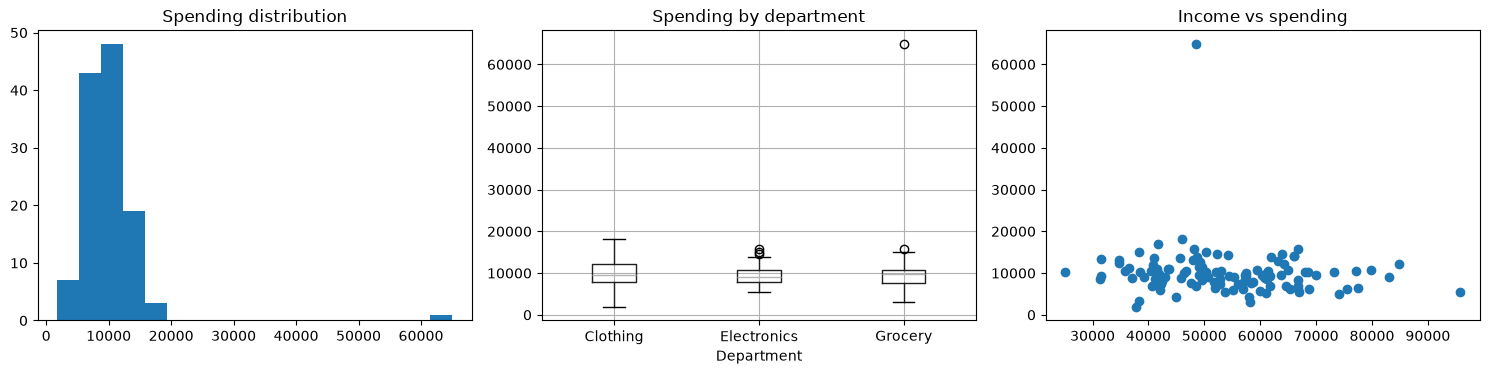

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["Monthly_Spend"].dropna(), bins=18)
axes[0].set_title("Spending distribution")
df.boxplot(column="Monthly_Spend", by="Department", ax=axes[1])
axes[1].set_title("Spending by department")
axes[2].scatter(df["Monthly_Income"], df["Monthly_Spend"])
axes[2].set_title("Income vs spending")
plt.suptitle("")
plt.tight_layout()
plt.show()

# 13. Identify Important Patterns
Compare mean spending and purchase percentages by membership to find patterns worth validating.

In [14]:
summary = df.groupby("Membership").agg(
    Customers=("Customer_ID", "count"),
    Avg_Spend=("Monthly_Spend", "mean"),
    Purchase_Rate=("Purchased", lambda x: (x == "Yes").mean()*100)
).round(1)
display(summary)


,Customers,Avg_Spend,Purchase_Rate
Membership,,,
Basic,72,10125.4,73.6
Gold,17,10735.8,88.2
Silver,32,9381.6,68.8


# 14. Write Business Insights
Convert calculated observations into business insights without assuming the sample data proves a real-world relationship.

In [15]:
top = df.groupby("Department")["Monthly_Spend"].mean().sort_values(ascending=False)
print(f"Observation: {top.index[0]} has the highest sample mean spend ({top.iloc[0]:,.0f}).")
print("Insight: Compare departments further before deciding where to focus marketing.")
print(f"Observation: {len(outliers)} spending values are flagged by the IQR rule.")
print("Insight: Verify unusually large transactions before using them for forecasting.")

Observation: Grocery has the highest sample mean spend (11,273).
Insight: Compare departments further before deciding where to focus marketing.
Observation: 6 spending values are flagged by the IQR rule.
Insight: Verify unusually large transactions before using them for forecasting.


# 15. Recommend Next Preprocessing Steps
Document what needs attention; do not actually clean or transform the dataset here.

In [16]:
print("1. Investigate missing Age and Monthly_Income; select imputation after reviewing missingness.")
print("2. Review exact duplicates and repeated Customer_ID values before deduplication.")
print("3. Verify unusually high spending against original transaction records.")
print("4. Consider encoding Department and Membership for modeling.")
print("5. Consider scaling numerical columns for scale-sensitive models.")
print("6. Split train/test data before fitting preprocessing transformations.")

1. Investigate missing Age and Monthly_Income; select imputation after reviewing missingness.
2. Review exact duplicates and repeated Customer_ID values before deduplication.
3. Verify unusually high spending against original transaction records.
4. Consider encoding Department and Membership for modeling.
5. Consider scaling numerical columns for scale-sensitive models.
6. Split train/test data before fitting preprocessing transformations.
